# 01 · Winds, stations and the balloon integrator

**Project:** What one Iceland launch buys.
**This notebook does four things:**

- **A.** Opens ERA5 winds from the cloud and checks they look like real winter weather.
- **B.** Loads the world's radiosonde stations and draws "the gap".
- **C.** Builds the balloon integrator and tests it on a wind field with a known exact answer.
- **D.** Flies one real balloon from Egilsstaðir to see it all working together.

**How to run it:** click a cell and press **Shift + Enter**. Run cells in order from the top. The kernel (top right) should say **Python (windborne)**.

Your method choices are in `decisions.md`.

In [4]:
import numpy as np                # arrays and maths
import pandas as pd               # tables
import xarray as xr               # gridded data (wind on a lat/lon/height grid)
import matplotlib.pyplot as plt   # charts
import cartopy.crs as ccrs        # map projections
import cartopy.feature as cfeature
from pathlib import Path
import urllib.request

R_EARTH = 6_371_000.0             # Earth's mean radius, metres
DATA = Path("data")               # local folder for downloaded files
DATA.mkdir(exist_ok=True)

# The gap region from decisions.md: 45 to 90N, 70W to 30E
GAP_LAT_MIN, GAP_LAT_MAX = 45.0, 90.0
GAP_LON_MIN, GAP_LON_MAX = -70.0, 30.0
GAP_KM = 500                      # main gap distance (300 and 800 are checks)

## A. Winds

The data is **ERA5**, ECMWF's reanalysis: a best estimate of the past atmosphere, made by blending observations into a weather model. We read WeatherBench2's copy:

- 1.5° grid (240 × 121 points)
- every 6 hours
- 13 pressure levels

It's read straight from Google Cloud, with no account needed.

**Note:** this copy ends on **10 Jan 2023**. Because of that, we use winters 2013/14 to 2021/22 (decided 17 Nov; see `decisions.md`).

In [5]:
WIND_STORE = ("gs://weatherbench2/datasets/era5/"
              "1959-2023_01_10-6h-240x121_equiangular_with_poles_conservative.zarr")

# open_zarr only reads the index; actual numbers download when we ask for them
era5 = xr.open_zarr(WIND_STORE, storage_options=dict(token="anon"))

print("first time:", era5.time.values[0])
print("last time: ", era5.time.values[-1])
print("levels (hPa):", era5.level.values)
print("grid:", era5.sizes["longitude"], "longitudes x", era5.sizes["latitude"], "latitudes")

first time: 1959-01-01T00:00:00.000000000
last time:  2023-01-10T18:00:00.000000000
levels (hPa): [  50  100  150  200  250  300  400  500  600  700  850  925 1000]
grid: 240 longitudes x 121 latitudes


### A1. One snapshot at 500 hPa

500 hPa is about 5.5 km up. Shading is wind speed; arrows show direction. We should see the westerly jet and its waves across the North Atlantic.

/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


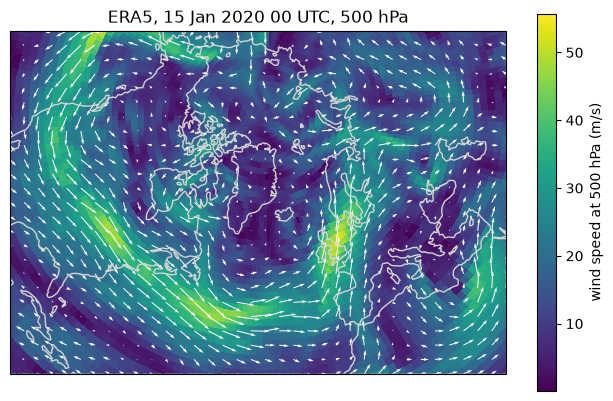

In [6]:
snap = era5[["u_component_of_wind", "v_component_of_wind"]].sel(
    time="2020-01-15T00", level=500).load()

# Longitudes are stored 0..358.5; shift to -180..180 so the Atlantic is in one piece
snap = snap.assign_coords(longitude=((snap.longitude + 180) % 360) - 180).sortby("longitude")
u = snap["u_component_of_wind"]      # eastward wind, m/s
v = snap["v_component_of_wind"]      # northward wind, m/s
speed = np.hypot(u, v)

proj = ccrs.NorthPolarStereo(central_longitude=-30)
fig, ax = plt.subplots(figsize=(8, 7), subplot_kw=dict(projection=proj))
ax.set_extent([-140, 40, 30, 90], crs=ccrs.PlateCarree())
mesh = ax.pcolormesh(speed.longitude, speed.latitude, speed.T,
                     transform=ccrs.PlateCarree(), cmap="viridis", shading="auto")
step = 4   # draw every 4th arrow so the map isn't cluttered
ax.quiver(u.longitude[::step], u.latitude[::step],
          u.T[::step, ::step].values, v.T[::step, ::step].values,
          transform=ccrs.PlateCarree(), color="white", scale=900, width=0.002,
          regrid_shape=25)   # resample arrows evenly on the map
ax.coastlines(color="lightgrey")
plt.colorbar(mesh, ax=ax, shrink=0.7, label="wind speed at 500 hPa (m/s)")
ax.set_title("ERA5, 15 Jan 2020 00 UTC, 500 hPa")
plt.show()

### A2. Check: is winter wind mostly from the west?

The average eastward wind `u` across every longitude, for January 2020, at our three levels. Physics says:
- `u` should be positive (westerly) through the mid latitudes.
- It should be strongest at 250 hPa, near the jet stream, around 30 to 45°N.

If not, something is wrong with how we're reading the data. This downloads about 200 MB, so allow 10 to 30 seconds.

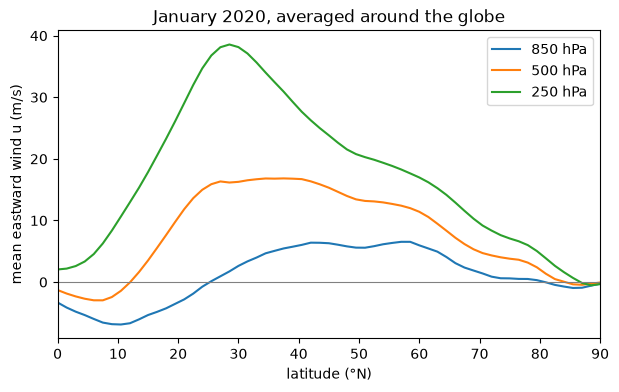

850 hPa: mean u over 40-65N = 5.9 m/s
500 hPa: mean u over 40-65N = 13.1 m/s
250 hPa: mean u over 40-65N = 20.3 m/s


In [7]:
LEVELS = [850, 500, 250]

jan_u = era5["u_component_of_wind"].sel(time=slice("2020-01-01", "2020-01-31"),
                                        level=LEVELS).load()
zonal_mean_u = jan_u.mean(dim=["time", "longitude"])     # average over time and longitude

fig, ax = plt.subplots(figsize=(7, 4))
for lev in LEVELS:
    ax.plot(zonal_mean_u.latitude, zonal_mean_u.sel(level=lev), label=f"{lev} hPa")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlim(0, 90)
ax.set_xlabel("latitude (°N)"); ax.set_ylabel("mean eastward wind u (m/s)")
ax.set_title("January 2020, averaged around the globe")
ax.legend(); plt.show()

band = zonal_mean_u.sel(latitude=slice(40, 65)).mean("latitude")
for lev in LEVELS:
    print(f"{lev} hPa: mean u over 40-65N = {float(band.sel(level=lev)):.1f} m/s")

## B. Radiosonde stations and the gap

NOAA's **IGRA2** list covers every weather balloon station on record. Each row includes the first and last year with data. Following `decisions.md`, a station counts as **active** if its last year is 2026.

In [8]:
STATION_URL = "https://www.ncei.noaa.gov/pub/data/igra/igra2-station-list.txt"
station_file = DATA / "igra2-station-list.txt"
if not station_file.exists():
    urllib.request.urlretrieve(STATION_URL, station_file)

# Fixed-width columns, positions from NOAA's igra2-list-format.txt
colspecs = [(0, 11), (12, 20), (21, 30), (31, 37), (41, 71), (72, 76), (77, 81), (82, 88)]
names = ["id", "lat", "lon", "elev_m", "name", "first_year", "last_year", "n_obs"]
stations = pd.read_fwf(station_file, colspecs=colspecs, names=names)

active = stations[stations.last_year >= 2026].copy()
print(len(stations), "stations on record,", len(active), "active in 2026")

# Who is active around the North Atlantic?
near = active[(active.lat > 55) & (active.lon > -75) & (active.lon < 35)]
near.sort_values("lon")[["id", "name", "lat", "lon", "first_year", "last_year"]]

2932 stations on record, 814 active in 2026


,id,name,lat,lon,first_year,last_year
381,CAM00071909,IQALUIT A; NU,63.7500,-68.5500,1946,2026
378,CAM00071906,KUUJJUAQ A; QUE,58.1000,-68.4167,1947,2026
331,CAM00071082,ALERT UA; NU,82.5000,-62.3333,1950,2026
859,GLM00004220,AASIAAT,68.7081,-52.8517,1950,2026
861,GLM00004270,MITTARFIK NARSARSUAQ,61.1667,-45.4167,1946,2026
866,GLM00004360,TASIILAQ,65.6111,-37.6367,1949,2026
864,GLM00004339,ITTOQQORTOORMIIT,70.4844,-21.9511,1946,2026
863,GLM00004320,DANMARKSHAVN,76.7694,-18.6681,1950,2026
1244,JNM00001001,JAN MAYEN (1001-1),70.9397,-8.6678,1949,2026
2128,UKM00003023,SOUTH UIST RANGE,57.3575,-7.3850,1998,2026


### B1. ⚠️ A problem with Iceland, and a decision for you

IGRA2 does not match what Iceland actually launches:

- **Keflavík is not in IGRA2 at all.** AIP Iceland GEN 3.5 says Keflavík launches twice a day.
- **Egilsstaðir's last year is 2024.** AIP ENR 5.3 says it launches daily from 1 Sep to 10 May.

Taken at face value, IGRA2 would make Iceland look like a hole in the network. **That would flatter Iceland**, because balloons launched there would count as "in the gap" from the start. That is exactly the kind of overstatement to avoid.

**Decision (17 Nov):** add both back as active stations, citing the AIP. The flag below does this. Set it to `False` to see the raw IGRA2 version.

In [9]:
ADD_ICELAND_STATIONS = True   # your decision: True = trust the AIP over IGRA2 for Iceland

extra = pd.DataFrame([
    # id is ours; coordinates: Keflavík from the brief, Egilsstaðir from IGRA2
    dict(id="AIP-KEF", name="KEFLAVIK (AIP GEN 3.5)",   lat=63.97, lon=-22.60),
    dict(id="AIP-EGS", name="EGILSSTADIR (AIP ENR 5.3)", lat=65.28, lon=-14.40),
])
if ADD_ICELAND_STATIONS:
    active = pd.concat([active[active.id != "ICM00004089"], extra], ignore_index=True)
print(len(active), "active stations used")

816 active stations used


### B2. Distance from every grid cell to its nearest station

**Great-circle distance (haversine formula):** the shortest distance between two points along the surface of a sphere. For each grid cell in the region, we find the distance to its nearest active station.

**The gap** is every cell where that distance is more than `GAP_KM`.

In [10]:
def great_circle_km(lat1, lon1, lat2, lon2):
    # Haversine distance in km between points given in degrees (works on arrays)
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R_EARTH / 1000 * np.arcsin(np.sqrt(a))


def nearest_station_km(grid_lat, grid_lon, st_lat, st_lon):
    # For each grid point, the distance to the closest station.
    # Broadcasting: grid points along one axis, stations along the other, then take the min.
    d = great_circle_km(grid_lat[:, None], grid_lon[:, None], st_lat[None, :], st_lon[None, :])
    return d.min(axis=1)


# Region grid on the same 1.5 degree spacing as the winds
region_lats = np.arange(GAP_LAT_MIN, GAP_LAT_MAX + 0.1, 1.5)
region_lons = np.arange(GAP_LON_MIN, GAP_LON_MAX + 0.1, 1.5)
LAT2D, LON2D = np.meshgrid(region_lats, region_lons, indexing="ij")

dist_km = nearest_station_km(LAT2D.ravel(), LON2D.ravel(),
                             active.lat.values, active.lon.values).reshape(LAT2D.shape)

for km in [300, 500, 800]:
    # weight each cell by cos(lat) because cells shrink towards the pole
    w = np.cos(np.radians(LAT2D))
    share = (w * (dist_km > km)).sum() / w.sum()
    print(f"gap at {km} km: {share:.0%} of the region's area")

gap at 300 km: 48% of the region's area
gap at 500 km: 25% of the region's area
gap at 800 km: 10% of the region's area


/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


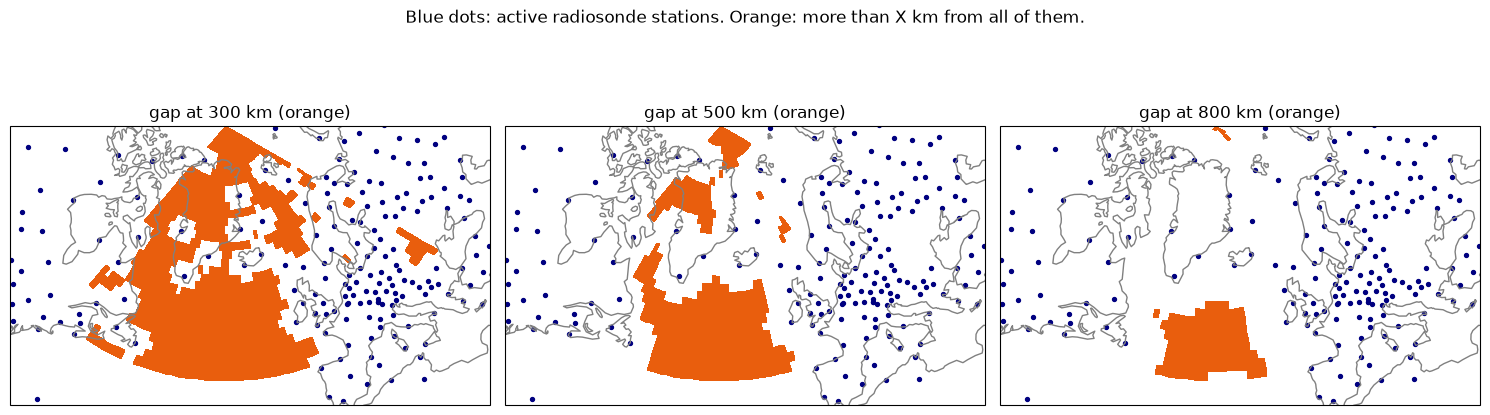

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), subplot_kw=dict(projection=proj))
for ax, km in zip(axes, [300, 500, 800]):
    ax.set_extent([-80, 40, 40, 90], crs=ccrs.PlateCarree())
    ax.pcolormesh(region_lons, region_lats, np.where(dist_km > km, 1.0, np.nan),
                  transform=ccrs.PlateCarree(), cmap="Oranges", vmin=0, vmax=1.5, shading="auto")
    ax.scatter(active.lon, active.lat, s=8, color="navy", transform=ccrs.PlateCarree())
    ax.coastlines(color="grey")
    ax.set_title(f"gap at {km} km (orange)")
plt.suptitle("Blue dots: active radiosonde stations. Orange: more than X km from all of them.")
plt.tight_layout(); plt.show()

## C. The balloon integrator

A balloon at a fixed pressure level drifts with the wind. On a sphere of radius R:

$$\frac{d\varphi}{dt} = \frac{v}{R}, \qquad \frac{d\lambda}{dt} = \frac{u}{R\cos\varphi}$$

- φ is latitude, λ is longitude (both in radians), u is eastward wind, v is northward wind.
- The `cos φ` is there because lines of longitude converge: a degree of longitude at 65°N is only about 42% as long as at the equator.

We step this forward with **RK4** (classical 4th-order Runge–Kutta), 1 hour per step.

In [12]:
def wrap_lon(lon_deg):
    # Keep longitude in [-180, 180) so crossing the dateline doesn't break anything
    return (lon_deg + 180.0) % 360.0 - 180.0


def drift_rate(lat_deg, u, v):
    # Rate of change of (lat, lon) in degrees per second, for wind u, v in m/s
    lat = np.radians(lat_deg)
    dlat_dt = v / R_EARTH                     # radians per second
    dlon_dt = u / (R_EARTH * np.cos(lat))     # longitude circles shrink by cos(lat)
    return np.degrees(dlat_dt), np.degrees(dlon_dt)


def rk4_step(wind, t, lat, lon, dt):
    # One RK4 step of length dt seconds. wind(t, lat, lon) returns (u, v) in m/s.
    def f(t, lat, lon):
        u, v = wind(t, lat, lon)
        return drift_rate(lat, u, v)

    k1 = f(t,          lat,                   lon)
    k2 = f(t + dt / 2, lat + dt / 2 * k1[0],  lon + dt / 2 * k1[1])
    k3 = f(t + dt / 2, lat + dt / 2 * k2[0],  lon + dt / 2 * k2[1])
    k4 = f(t + dt,     lat + dt * k3[0],      lon + dt * k3[1])

    new_lat = lat + dt / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
    new_lon = lon + dt / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return new_lat, wrap_lon(new_lon)


def fly(wind, lat0, lon0, t0, hours, dt_hours=1.0, pole_stop=88.0):
    # Fly one or many balloons from (lat0, lon0) starting at time t0 (seconds).
    # Returns arrays of shape (n_steps + 1, n_balloons). A balloon that gets within
    # (90 - pole_stop) degrees of a pole is stopped and gets NaN from then on,
    # because dlon/dt blows up as cos(lat) goes to 0.
    lat = np.atleast_1d(np.asarray(lat0, dtype=float)).copy()
    lon = np.atleast_1d(np.asarray(lon0, dtype=float)).copy()
    dt = dt_hours * 3600.0
    n_steps = int(round(hours / dt_hours))

    lats = np.full((n_steps + 1, lat.size), np.nan)
    lons = np.full((n_steps + 1, lat.size), np.nan)
    lats[0], lons[0] = lat, lon
    alive = np.abs(lat) < pole_stop

    for i in range(n_steps):
        t = t0 + i * dt
        if alive.any():
            lat[alive], lon[alive] = rk4_step(wind, t, lat[alive], lon[alive], dt)
        alive &= np.abs(lat) < pole_stop
        lats[i + 1, alive], lons[i + 1, alive] = lat[alive], lon[alive]

    hours_since_launch = np.arange(n_steps + 1) * dt_hours
    return hours_since_launch, lats, lons

### C1. Test: solid-body rotation about a tilted axis

To test the integrator we need a wind field whose exact answer we know. We use the whole atmosphere spinning as a rigid shell about an axis tilted 30° from the pole (Williamson et al. 1992, test case 1):

$$u = U_0(\cos\varphi\cos\alpha + \sin\varphi\cos\lambda\sin\alpha), \qquad v = -U_0\sin\lambda\sin\alpha$$

- **Exact answer:** the start point rotated about the tilted axis. After one period, T = 2πR/U₀, it's back where it started.
- **Why this is a hard test:** the balloon changes latitude, crosses the dateline and swings close to the equator. All of the formula above gets used.
- **Convergence check:** RK4 is 4th order, so halving the step should cut the error by about 2⁴ = 16.

In [13]:
PERIOD_S = 12 * 86400                       # one full lap in 12 days
U0 = 2 * np.pi * R_EARTH / PERIOD_S         # ~38.6 m/s, a realistic jet speed
ALPHA = np.radians(30)                      # tilt of the rotation axis from the pole


def rotation_wind(t, lat_deg, lon_deg):
    lat, lon = np.radians(lat_deg), np.radians(lon_deg)
    u = U0 * (np.cos(lat) * np.cos(ALPHA) + np.sin(lat) * np.cos(lon) * np.sin(ALPHA))
    v = -U0 * np.sin(lon) * np.sin(ALPHA)
    return u, v


def exact_rotation(lat0, lon0, t):
    # Rotate the start point about the axis k = (-sin a, 0, cos a) by angle (U0/R) t,
    # using Rodrigues' rotation formula.
    lat0, lon0 = np.radians(lat0), np.radians(lon0)
    r = np.array([np.cos(lat0) * np.cos(lon0), np.cos(lat0) * np.sin(lon0), np.sin(lat0)])
    k = np.array([-np.sin(ALPHA), 0.0, np.cos(ALPHA)])
    th = (U0 / R_EARTH) * np.asarray(t)[:, None]
    r_rot = (r * np.cos(th) + np.cross(k, r) * np.sin(th)
             + k * (k @ r) * (1 - np.cos(th)))
    lat = np.degrees(np.arcsin(r_rot[:, 2]))
    lon = np.degrees(np.arctan2(r_rot[:, 1], r_rot[:, 0]))
    return lat, lon


START_LAT, START_LON = 45.0, 0.0
errors = {}
for dt_h in [2.0, 1.0, 0.5]:
    hrs, lats, lons = fly(rotation_wind, START_LAT, START_LON, t0=0.0, hours=12 * 24, dt_hours=dt_h)
    ex_lat, ex_lon = exact_rotation(START_LAT, START_LON, hrs * 3600)
    err = great_circle_km(lats[:, 0], lons[:, 0], ex_lat, ex_lon)
    errors[dt_h] = err.max()
    print(f"step {dt_h:>3} h: worst error over 12 days = {err.max():.2e} km; "
          f"back at start to within {great_circle_km(lats[-1,0], lons[-1,0], START_LAT, START_LON):.2e} km")

print(f"\nerror ratio 2h/1h:   {errors[2.0] / errors[1.0]:.1f}  (RK4 theory: ~16)")
print(f"error ratio 1h/0.5h: {errors[1.0] / errors[0.5]:.1f}  (RK4 theory: ~16)")

step 2.0 h: worst error over 12 days = 3.19e-05 km; back at start to within 2.15e-05 km
step 1.0 h: worst error over 12 days = 1.97e-06 km; back at start to within 1.34e-06 km
step 0.5 h: worst error over 12 days = 1.22e-07 km; back at start to within 8.39e-08 km

error ratio 2h/1h:   16.2  (RK4 theory: ~16)
error ratio 1h/0.5h: 16.1  (RK4 theory: ~16)


/opt/anaconda3/envs/windborne/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


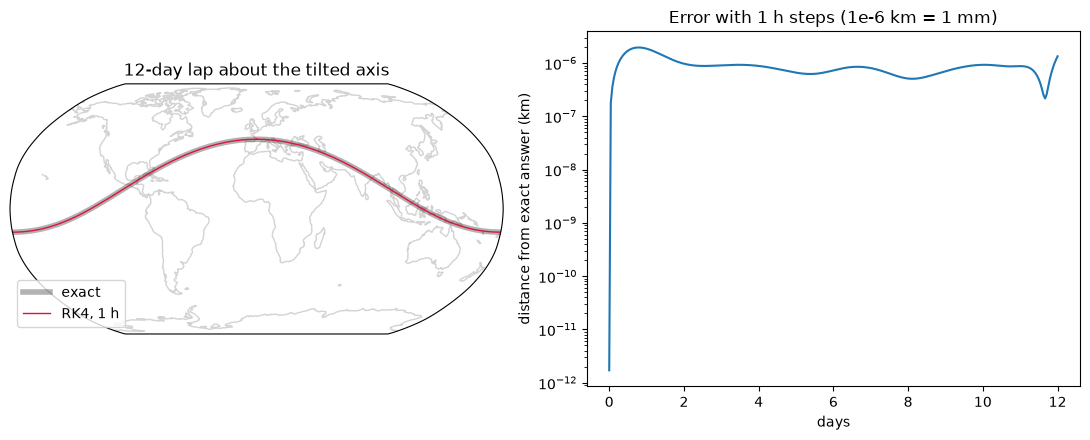

In [14]:
hrs, lats, lons = fly(rotation_wind, START_LAT, START_LON, t0=0.0, hours=12 * 24, dt_hours=1.0)
ex_lat, ex_lon = exact_rotation(START_LAT, START_LON, hrs * 3600)

fig = plt.figure(figsize=(11, 4.5))
ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.Robinson())
ax1.set_global(); ax1.coastlines(color="lightgrey")
ax1.plot(ex_lon, ex_lat, color="black", lw=4, alpha=0.3, transform=ccrs.Geodetic(), label="exact")
ax1.plot(lons[:, 0], lats[:, 0], color="crimson", lw=1, transform=ccrs.Geodetic(), label="RK4, 1 h")
ax1.legend(loc="lower left"); ax1.set_title("12-day lap about the tilted axis")

ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogy(hrs / 24, great_circle_km(lats[:, 0], lons[:, 0], ex_lat, ex_lon) + 1e-12)
ax2.set_xlabel("days"); ax2.set_ylabel("distance from exact answer (km)")
ax2.set_title("Error with 1 h steps (1e-6 km = 1 mm)")
plt.tight_layout(); plt.show()

## D. Putting it together: one real balloon

To fly in real winds, we need the wind at any time and place, not only at the grid points. We use:

- **Bilinear interpolation in space:** a weighted average of the 4 surrounding grid points.
- **Linear interpolation in time:** a weighted average of the 6-hourly snapshots either side.

The function below is written for arrays, so tomorrow it can fly hundreds of balloons at once.

In [15]:
def load_winds(start, end, level):
    # Download u and v at one pressure level between two dates, as numpy arrays (time, lon, lat)
    block = era5[["u_component_of_wind", "v_component_of_wind"]].sel(
        time=slice(start, end), level=level).load()
    t_seconds = (block.time.values - block.time.values[0]) / np.timedelta64(1, "s")
    return dict(u=block["u_component_of_wind"].values, v=block["v_component_of_wind"].values,
                t=t_seconds, t0=block.time.values[0])


def make_wind(w, grid_step=1.5, n_lon=240, n_lat=121):
    # Returns wind(t, lat, lon) that interpolates the gridded block w.
    # Grid: lon = 0, 1.5, ..., 358.5 and lat = -90, -88.5, ..., 90.
    dt_grid = w["t"][1] - w["t"][0]          # 6 hours, in seconds

    def bilinear(field, lat, lon):
        x = (lon % 360.0) / grid_step        # fractional index along longitude
        y = (lat + 90.0) / grid_step         # fractional index along latitude
        i0 = np.floor(x).astype(int); fx = x - i0
        j0 = np.clip(np.floor(y).astype(int), 0, n_lat - 2); fy = y - j0
        i0 = i0 % n_lon; i1 = (i0 + 1) % n_lon   # wrap around the globe in longitude
        return ((1 - fx) * (1 - fy) * field[i0, j0] + fx * (1 - fy) * field[i1, j0]
                + (1 - fx) * fy * field[i0, j0 + 1] + fx * fy * field[i1, j0 + 1])

    def wind(t, lat, lon):
        k = min(int(t // dt_grid), len(w["t"]) - 2)   # snapshot just before t
        a = (t - w["t"][k]) / dt_grid                 # 0 at snapshot k, 1 at snapshot k+1
        u = (1 - a) * bilinear(w["u"][k], lat, lon) + a * bilinear(w["u"][k + 1], lat, lon)
        v = (1 - a) * bilinear(w["v"][k], lat, lon) + a * bilinear(w["v"][k + 1], lat, lon)
        return u, v

    return wind

### D1. Egilsstaðir and Cambridge, launched 15 Jan 2020 00 UTC, 7 days, passive at each level

This is not a result yet, just one day's weather. It checks that balloons go roughly east and that the three levels behave differently.

Egilsstaðir   850 hPa: ends at  63.4N   11.4E, travelled 4,691 km (mean 8 m/s)
Cambridge MA  850 hPa: ends at  66.4N   27.1E, travelled 9,947 km (mean 16 m/s)
Egilsstaðir   500 hPa: ends at  35.8N   32.5E, travelled 7,804 km (mean 13 m/s)
Cambridge MA  500 hPa: ends at  20.9N   43.3E, travelled 11,264 km (mean 19 m/s)
Egilsstaðir   250 hPa: ends at  81.4N   59.8E, travelled 10,667 km (mean 18 m/s)
Cambridge MA  250 hPa: ends at  46.3N -139.0E, travelled 27,383 km (mean 45 m/s)


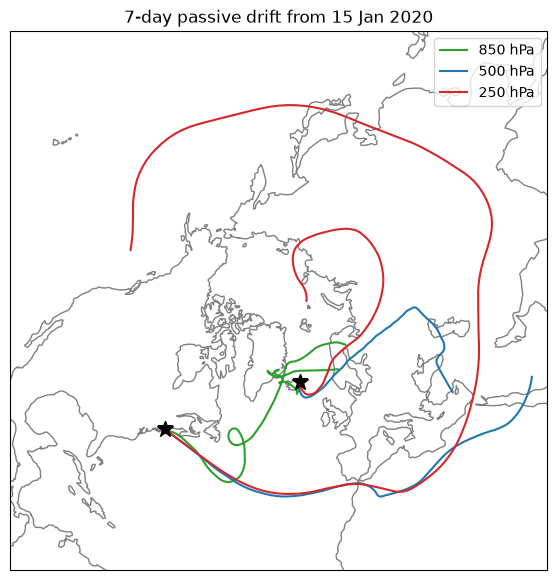

In [16]:
SITES = {"Egilsstaðir": (65.28, -14.40), "Cambridge MA": (42.36, -71.09)}
LAUNCH, END = "2020-01-15T00", "2020-01-22T06"

fig, ax = plt.subplots(figsize=(9, 7), subplot_kw=dict(projection=proj))
ax.set_extent([-180, 180, 20, 90], crs=ccrs.PlateCarree())
ax.coastlines(color="grey")
colours = {850: "tab:green", 500: "tab:blue", 250: "tab:red"}

for lev in LEVELS:
    wind = make_wind(load_winds(LAUNCH, END, lev))
    for site, (lat0, lon0) in SITES.items():
        hrs, lats, lons = fly(wind, lat0, lon0, t0=0.0, hours=7 * 24)
        ax.plot(lons[:, 0], lats[:, 0], color=colours[lev], transform=ccrs.Geodetic(),
                label=f"{lev} hPa" if site == "Egilsstaðir" else None)
        # distance travelled = sum of the hour-by-hour great-circle hops
        path_km = np.nansum(great_circle_km(lats[:-1, 0], lons[:-1, 0], lats[1:, 0], lons[1:, 0]))
        print(f"{site:13s} {lev} hPa: ends at {lats[-1,0]:5.1f}N {lons[-1,0]:6.1f}E,"
              f" travelled {path_km:,.0f} km (mean {path_km / (7 * 86.4):.0f} m/s)")

for site, (lat0, lon0) in SITES.items():
    ax.plot(lon0, lat0, "k*", ms=12, transform=ccrs.PlateCarree())
ax.legend(); ax.set_title("7-day passive drift from 15 Jan 2020")
plt.show()

## Summary

**Should be true if you ran every cell:**
- Winter winds are westerly, and strongest at 250 hPa.
- The integrator matches the exact rotation, and the error drops by about 16 when the step halves.
- Real balloons drift east.

**Decided 17 Nov** (see `decisions.md`):
1. **Iceland stations.** Keflavík and Egilsstaðir are added back as active stations, following the AIP, because IGRA2 leaves them out.
2. **Season.** Winters 2013/14 to 2021/22, because this copy of the data ends on 10 Jan 2023.